# KTPM-BTL: executed Kaggle CPU benchmark
Source: 298d97fcd96d0bb89c617bba782f47d2a4f23584

In [1]:
from pathlib import Path
import os, sys, subprocess, json, datetime, shutil
assert Path('/kaggle/working').is_dir(), 'Run on Kaggle CPU'
ROOT=Path('/kaggle/working/KTPM-BTL')
COMMIT='298d97fcd96d0bb89c617bba782f47d2a4f23584'
REPO='https://github.com/FlowBoat123/KTPM-BTL.git'
if not (ROOT/'.git').exists():
    subprocess.run(['git','clone','--no-checkout',REPO,str(ROOT)],check=True)
subprocess.run(['git','-C',str(ROOT),'fetch','origin',COMMIT],check=True)
subprocess.run(['git','-C',str(ROOT),'checkout','--detach',COMMIT],check=True)
assert subprocess.check_output(['git','-C',str(ROOT),'rev-parse','HEAD'],text=True).strip()==COMMIT
gpu=subprocess.run(['nvidia-smi','--query-gpu=name','--format=csv,noheader'],capture_output=True,text=True) if shutil.which('nvidia-smi') else None
assert gpu is None or gpu.returncode!=0 or not gpu.stdout.strip(), 'Choose Accelerator None'
print('Source commit:', COMMIT)


Source commit: 298d97fcd96d0bb89c617bba782f47d2a4f23584


From https://github.com/FlowBoat123/KTPM-BTL
 * branch            298d97fcd96d0bb89c617bba782f47d2a4f23584 -> FETCH_HEAD
HEAD is now at 298d97f feat: add fixed-admin workload and concise phase 1 submission docs


In [2]:
JAVA_HOME=Path('/usr/lib/jvm/java-17-openjdk-amd64')
if not (JAVA_HOME/'bin/java').exists():
    subprocess.run(['apt-get','update','-qq'],check=True,stdout=subprocess.DEVNULL)
    subprocess.run(['apt-get','install','-y','openjdk-17-jdk-headless'],check=True,stdout=subprocess.DEVNULL)
os.environ['JAVA_HOME']=str(JAVA_HOME)
os.environ['PATH']=str(JAVA_HOME/'bin')+os.pathsep+os.environ['PATH']
subprocess.run([sys.executable,'-m','pip','install','-q','-r',str(ROOT/'requirements-load.txt')],check=True)
(ROOT/'mvnw').chmod(0o755)
with Path('/kaggle/working/build.log').open('w') as log:
    build=subprocess.run([str(ROOT/'mvnw'),'-B','verify'],cwd=ROOT,stdout=log,stderr=subprocess.STDOUT)
print('\n'.join(Path('/kaggle/working/build.log').read_text().splitlines()[-20:]))
assert build.returncode==0, 'Build/test failed'


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.10.8 which is incompatible.


[INFO] Downloading from central: https://repo.maven.apache.org/maven2/org/ow2/asm/asm-commons/9.7/asm-commons-9.7.jar
[INFO] Downloaded from central: https://repo.maven.apache.org/maven2/org/antlr/antlr4-runtime/4.7.2/antlr4-runtime-4.7.2.jar (338 kB at 3.5 MB/s)
[INFO] Downloading from central: https://repo.maven.apache.org/maven2/org/ow2/asm/asm-tree/9.7/asm-tree-9.7.jar
[INFO] Downloaded from central: https://repo.maven.apache.org/maven2/org/apache/maven/plugins/maven-shade-plugin/3.6.0/maven-shade-plugin-3.6.0.jar (150 kB at 1.4 MB/s)
[INFO] Downloading from central: https://repo.maven.apache.org/maven2/org/jdom/jdom2/2.0.6.1/jdom2-2.0.6.1.jar
[INFO] Downloaded from central: https://repo.maven.apache.org/maven2/org/ow2/asm/asm/9.7/asm-9.7.jar (125 kB at 1.2 MB/s)
[INFO] Downloading from central: https://repo.maven.apache.org/maven2/org/vafer/jdependency/2.10/jdependency-2.10.jar
[INFO] Downloaded from central: https://repo.maven.apache.org/maven2/org/ow2/asm/asm-commons/9.7/asm-com

In [3]:
SCENARIOS=[(100,5),(200,10),(500,20)]  # customers, distinct doctors; exactly one admin
DURATION=120
WARMUP=15
SPAWN_RATE=50
RUN_ID=datetime.datetime.now(datetime.timezone.utc).strftime('%Y%m%dT%H%M%SZ')
OUTPUT_ROOT=Path('/kaggle/working')/('fixed-admin-'+RUN_ID)
OUTPUT_ROOT.mkdir()
RESULTS=[]
for customers,doctors in SCENARIOS:
    output=OUTPUT_ROOT/f'customers-{customers}-doctors-{doctors}'
    print(f'Start: admin=1, doctors={doctors}, customers={customers}',flush=True)
    run=subprocess.run([sys.executable,str(ROOT/'scripts/run_load_test.py'),
        '--environment','kaggle','--customers',str(customers),'--doctors',str(doctors),
        '--spawn-rate',str(SPAWN_RATE),'--warmup',str(WARMUP),'--duration',str(DURATION),
        '--output',str(output)],cwd=ROOT)
    meta=json.loads((output/'metadata.json').read_text())
    summary=json.loads((output/'summary.json').read_text()) if (output/'summary.json').exists() else {}
    phases=json.loads((output/'phases.json').read_text()) if (output/'phases.json').exists() else {}
    expected={'AdminUser':1,'DoctorUser':doctors,'CustomerUser':customers}
    assert meta['commit']==COMMIT and meta['working_tree']=='', 'Source changed'
    assert phases.get('observed_counts_at_end')==expected, 'Wrong role populations'
    row={'customers':customers,'doctors':doctors,'admins':1,'total_users':1+customers+doctors,
         'exit_code':run.returncode,**summary}
    RESULTS.append(row)
    (OUTPUT_ROOT/'comparison.json').write_text(json.dumps(RESULTS,indent=2))
    print(json.dumps(row),flush=True)
    assert 'requests' in summary, 'Run failed; inspect logs'
Path('/kaggle/working/latest-fixed-admin-output.txt').write_text(str(OUTPUT_ROOT))


Start: admin=1, doctors=5, customers=100


{
  "requests": 16280,
  "failures": 0,
  "failure_ratio": 0.0,
  "rps": 135.60711831627262,
  "mean_ms": 6.5275763218057525,
  "p95_ms": 22.0,
  "target_met": true,
  "measurement_elapsed_seconds": 120.05269488900001
}
Report: /kaggle/working/fixed-admin-20261026T100524Z/customers-100-doctors-5/REPORT.md
Evidence bundle: /kaggle/working/fixed-admin-20261026T100524Z/customers-100-doctors-5.zip
{"customers": 100, "doctors": 5, "admins": 1, "total_users": 106, "exit_code": 0, "requests": 16280, "failures": 0, "failure_ratio": 0.0, "rps": 135.60711831627262, "mean_ms": 6.5275763218057525, "p95_ms": 22.0, "target_met": true, "measurement_elapsed_seconds": 120.05269488900001}


Start: admin=1, doctors=10, customers=200


{
  "requests": 32477,
  "failures": 0,
  "failure_ratio": 0.0,
  "rps": 270.5010202833227,
  "mean_ms": 10.261860780706572,
  "p95_ms": 32.0,
  "target_met": true,
  "measurement_elapsed_seconds": 120.062393724
}
Report: /kaggle/working/fixed-admin-20261026T100524Z/customers-200-doctors-10/REPORT.md
Evidence bundle: /kaggle/working/fixed-admin-20261026T100524Z/customers-200-doctors-10.zip
{"customers": 200, "doctors": 10, "admins": 1, "total_users": 211, "exit_code": 0, "requests": 32477, "failures": 0, "failure_ratio": 0.0, "rps": 270.5010202833227, "mean_ms": 10.261860780706572, "p95_ms": 32.0, "target_met": true, "measurement_elapsed_seconds": 120.062393724}


Start: admin=1, doctors=20, customers=500


{
  "requests": 68116,
  "failures": 0,
  "failure_ratio": 0.0,
  "rps": 566.486534099108,
  "mean_ms": 147.19599671268173,
  "p95_ms": 310.0,
  "target_met": true,
  "measurement_elapsed_seconds": 120.24292882500004
}
Report: /kaggle/working/fixed-admin-20261026T100524Z/customers-500-doctors-20/REPORT.md
Evidence bundle: /kaggle/working/fixed-admin-20261026T100524Z/customers-500-doctors-20.zip
{"customers": 500, "doctors": 20, "admins": 1, "total_users": 521, "exit_code": 0, "requests": 68116, "failures": 0, "failure_ratio": 0.0, "rps": 566.486534099108, "mean_ms": 147.19599671268173, "p95_ms": 310.0, "target_met": true, "measurement_elapsed_seconds": 120.24292882500004}


44

# Kaggle CPU: one admin, distinct doctors

Source commit: 298d97fcd96d0bb89c617bba782f47d2a4f23584
Same sessions across login/warm-up/measurement. Warm-up 15s AFTER every session is ready; measure 120s plus draining in-flight requests. See phases.json for actual elapsed time. Fresh backend/DB per scenario.

| Customers | Doctors | Admin | Total | Requests | Failures | RPS | Mean ms | P95 ms |
| ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 100 | 5 | 1 | 106 | 16280 | 0 | 135.61 | 6.53 | 22 |
| 200 | 10 | 1 | 211 | 32477 | 0 | 270.50 | 10.26 | 32 |
| 500 | 20 | 1 | 521 | 68116 | 0 | 566.49 | 147.20 | 310 |

Customers read/book/look up; 20% of new bookings cancel immediately. One admin reads and assigns pending bookings. Distinct doctors read/confirm/complete their own cases. Think time 1–2.5s per task.

Login/startup metrics are in setup_stats.csv; measurement excludes login/warm-up. Backend and Locust share CPU; not maximum capacity. One admin may leave a growing pending queue. Historical 7/2/1 results are a different workload, not a before/after optimization comparison.

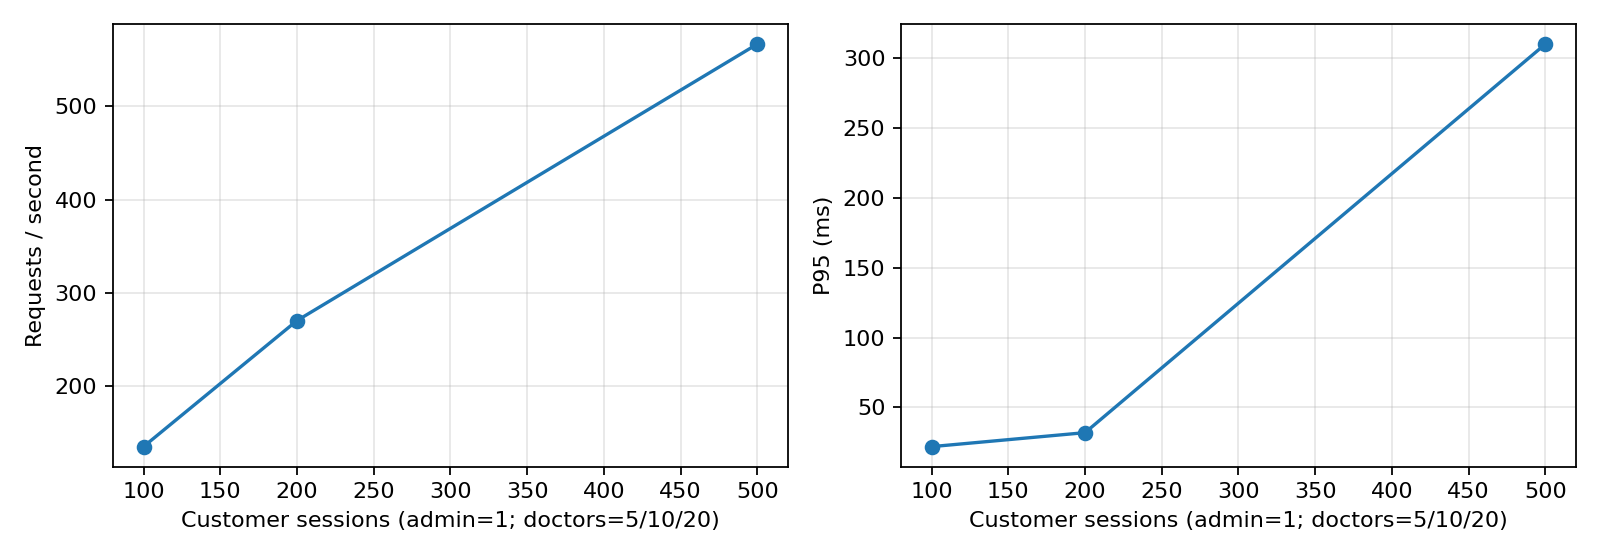

In [4]:
from IPython.display import display, Markdown, Image
import csv
import matplotlib.pyplot as plt
with (OUTPUT_ROOT/'comparison.csv').open('w',newline='') as stream:
    writer=csv.DictWriter(stream,fieldnames=list(RESULTS[0]));writer.writeheader();writer.writerows(RESULTS)
lines=['# Kaggle CPU: one admin, distinct doctors', '', 'Source commit: '+COMMIT,
       'Same sessions across login/warm-up/measurement. Warm-up 15s AFTER every session is ready; measure 120s plus draining in-flight requests. See phases.json for actual elapsed time. Fresh backend/DB per scenario.',
       '', '| Customers | Doctors | Admin | Total | Requests | Failures | RPS | Mean ms | P95 ms |',
       '| ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |']
for r in RESULTS:
    lines.append('| {customers} | {doctors} | {admins} | {total_users} | {requests} | {failures} | {rps:.2f} | {mean_ms:.2f} | {p95_ms:.0f} |'.format(**r))
lines+=['', 'Customers read/book/look up; 20% of new bookings cancel immediately. One admin reads and assigns pending bookings. Distinct doctors read/confirm/complete their own cases. Think time 1–2.5s per task.',
        '', 'Login/startup metrics are in setup_stats.csv; measurement excludes login/warm-up. Backend and Locust share CPU; not maximum capacity. One admin may leave a growing pending queue. Historical 7/2/1 results are a different workload, not a before/after optimization comparison.']
(OUTPUT_ROOT/'REPORT.md').write_text('\n'.join(lines))
display(Markdown('\n'.join(lines)))
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
for ax,key,label in zip(axes,['rps','p95_ms'],['Requests / second','P95 (ms)']):
    ax.plot([r['customers'] for r in RESULTS],[r[key] for r in RESULTS],marker='o')
    ax.set_xlabel('Customer sessions (admin=1; doctors=5/10/20)');ax.set_ylabel(label);ax.grid(alpha=.3)
fig.tight_layout();fig.savefig(OUTPUT_ROOT/'scaling.png',dpi=160);plt.close(fig)
display(Image(filename=str(OUTPUT_ROOT/'scaling.png')))
